# 621. Task Scheduler
**Difficulty:** 🟡 Medium · **Topic:** Heap · **Pattern:** [Heap Simulation](README.md) · **LeetCode:** https://leetcode.com/problems/task-scheduler/

## 💡 Concepts

**Core concept(s):** **Heap simulation with a cooldown queue** — simulate the CPU, always running the available task type with the **most copies left**; a **max-heap** picks it, and a **FIFO queue** parks task types that are cooling down until they may run again.

**Why it applies here:**
- The greedy rule "run the type with the most copies left" is what keeps idle time lowest: the biggest pile is the one that would otherwise force idles at the end.
- "Most copies left, among the ones allowed right now" is a repeated *take the max* → max-heap.
- A type that just ran is **not allowed** for the next `n` ticks. Each one leaves in the order it ran and becomes free exactly `n` ticks later, so a plain queue holds them in release order.

**Key intuition:**
- Only the **counts** matter, not the letters: the heap stores "copies left" per type.
- Each tick: pop the biggest count, run one copy, and if copies remain, park it in the cooldown queue with the tick when it may return.
- If nothing is runnable, the CPU idles; jump the clock straight to the tick when the queue's front is released instead of ticking through idle time one by one.
- A **counting formula** gives the same number in `O(T)` without simulating (Approach 3). It answers only "how long", and it is derived from the picture the simulation draws.

---

### 📚 What is a Heap / Priority Queue?
- A **priority queue** always hands out the most important item next (the smallest or the largest).
- A **binary heap** stores it as a complete binary tree in a list: index `i` has children `2i+1`, `2i+2`, and every parent beats its children, so the best item is at index `0`.
- **Key operations:** peek **O(1)**; push / pop **O(log k)** for `k` items; `heapify` a list **O(k)**.
- **In Python:** `heapq` on a plain `list`, **min-heap only**. For a max-heap, push **negated** counts and negate again when you pop.

### 📚 What is a Queue / `deque`?
- A **queue** is first in, first out: add at the back, remove from the front.
- Here every task type enters cooldown at a later tick than the one before it, with the same cooldown length `n`, so the front of the queue is always the **next one to be released**.
- **Key operations:** `append` and `popleft` are **O(1)**; peek the front with `q[0]`.
- **In Python:** `collections.deque` (a plain `list.pop(0)` is `O(n)`).

### 📚 What is a Hash Map / `Counter`?
- A **hash map** stores key → value pairs and finds a key in **O(1)** on average by hashing it to a slot.
- `collections.Counter(tasks)` is a hash map from each task type to how many times it appears, built in one **O(T)** pass.
- We only need its `.values()`: the counts.

### 📚 What is a Greedy choice?
- A **greedy** algorithm makes the locally best choice at every step and never revisits it.
- Here: at every tick, run the allowed task type with the **most copies left**. Leaving the largest pile for later is what creates idle ticks at the end; draining it first lets the small piles fill the gaps.
- Greedy needs a reason to be correct. Here the reason is the lower bound in Approach 3: the simulation always reaches it, and the randomised check below confirms the two agree.

---

**Prerequisite knowledge:**
- [Last Stone Weight](last_stone_weight.ipynb): the basic max-heap simulation loop (pop the best, act, push back).
- `heapq` basics, covered in [Heaps & Priority Queues](../../../deep_dive/12_Heaps_Priority_Queues/README.md).

## 📝 Problem

A CPU must run a list of `tasks`, each a capital letter. Each **interval** (tick) it can run one task or stay **idle**. Two runs of the **same** task type must be at least `n` intervals apart (at least `n` other intervals in between). Tasks can run in any order. Return the **minimum number of intervals** needed to finish every task.

**Example 1**
```
tasks = ["A","A","A","B","B","B"], n = 2  ->  8
A B idle A B idle A B
```

**Example 2**
```
tasks = ["A","C","A","B","D","B"], n = 1  ->  6
A B A B C D        (no idle needed)
```

**Example 3**
```
tasks = ["A","A","A","B","B","B"], n = 3  ->  10
A B idle idle A B idle idle A B
```

**Constraints:** `1 <= tasks.length <= 10⁴`, `tasks[i]` is an uppercase English letter, `0 <= n <= 100`.

> Three approaches: a tick-by-tick simulation that scans every type for the best one (`O(ticks·k)`), the max-heap + cooldown-queue simulation that is this pattern's template (`O(T log k)`), and a closed-form counting formula (`O(T)`). `T` = number of tasks, `k` = number of distinct task types.

In [1]:
import heapq
import random
from collections import Counter, deque
from typing import List, Hashable

### Approach 1 — Brute Force: simulate every tick, scan every type

**Idea:**
1. Count the copies of each type and remember, per type, the earliest tick it may run (`ready_at`, all `0` at the start).
2. For each tick, scan **all** types: among those with copies left and `ready_at <= tick`, pick the one with the most copies left.
3. If one is found, run it: one copy fewer, and `ready_at = tick + n + 1`. If none is found, the tick is idle.
4. Stop when no copies are left; the number of ticks used is the answer.

**Time complexity:** `O(ticks · k)` — every tick scans all `k` types, and `ticks` is the answer itself (between `T` and about `T·(n+1)`). On LeetCode `k <= 26`, but with arbitrary labels `k` can grow with `T`, and then this becomes `O(T²)`.

**Space complexity:** `O(k)` — one count and one `ready_at` per type.

In [2]:
def least_interval_brute(tasks: List[Hashable], n: int) -> int:
    remaining = Counter(tasks)                 # type -> copies left
    ready_at = {t: 0 for t in remaining}       # type -> earliest tick it may run again
    left, tick = len(tasks), 0
    while left:
        best = None
        for t, c in remaining.items():         # O(k) scan on every single tick
            if c and ready_at[t] <= tick and (best is None or c > remaining[best]):
                best = t                       # allowed now and has the most copies left
        if best is not None:
            remaining[best] -= 1
            ready_at[best] = tick + n + 1      # must wait n full ticks before running again
            left -= 1
        tick += 1                              # if best is None, this tick was idle
    return tick

### Approach 2 — Max-heap + cooldown queue (pattern template · interview target)

**Idea:** the [Heap Simulation](README.md) template — pop the best, act, push back — with one twist: what you would push back must first **wait** in a cooldown queue.
1. Build a max-heap of the counts (negated, because `heapq` is a min-heap). Labels are not needed.
2. Loop while the heap or the cooldown queue still holds work. Advance the clock: `time += 1`.
3. If the heap is not empty, pop the biggest count and run one copy. If copies remain, append `(count_left, time + n)` to the cooldown queue: it may rejoin the heap once tick `time + n` is over.
4. If the heap is empty, every remaining type is cooling down: the CPU idles. Jump the clock to the front's release tick, `time = cooldown[0][1]`, instead of looping through each idle tick.
5. If the queue's front is released at this tick, push its count back into the heap.
6. When both are empty, `time` is the answer.

**Time complexity:** `O(T log k)` — each of the `T` task runs does one heap pop and at most one push (`O(log k)`), and the jump means idle stretches cost one loop pass each, not one per idle tick. Counting is `O(T)`.

**Space complexity:** `O(k)` — the heap and the queue together hold at most one entry per type.

> This is the approach to write in an interview: it is the pattern's template, it explains *why* the greedy works, and it extends to variants that need the actual schedule (Reorganize String) where no formula exists.

In [3]:
def least_interval_heap(tasks: List[Hashable], n: int) -> int:
    heap = [-c for c in Counter(tasks).values()]   # max-heap of copies left (negated)
    heapq.heapify(heap)
    cooldown = deque()                             # (negated copies left, tick it is released)
    time = 0
    while heap or cooldown:
        time += 1
        if heap:
            cnt = heapq.heappop(heap) + 1          # run one copy of the biggest pile (+1 because negated)
            if cnt:                                # copies remain: park it for n ticks
                cooldown.append((cnt, time + n))
        else:
            time = cooldown[0][1]                  # nothing runnable: idle until the front is released
        if cooldown and cooldown[0][1] == time:    # front's cooldown ends this tick
            heapq.heappush(heap, cooldown.popleft()[0])
    return time

### Approach 3 — Counting formula (closed form)

**Idea:** read the answer off the picture the simulation draws.
1. Let `maxf` be the highest count, and `count_max` the number of types that have it.
2. The most frequent type forces `maxf - 1` full **frames** of length `n + 1` (the task, then `n` slots before it may run again), plus a last partial frame.
3. The last frame holds one copy of each of the `count_max` most frequent types. So at least `(maxf - 1) * (n + 1) + count_max` intervals are needed.
4. Other tasks fill the idle slots. If there are more tasks than slots, there is no idle at all and the answer is simply `len(tasks)`.
5. Answer: `max(len(tasks), (maxf - 1) * (n + 1) + count_max)`.

```
tasks = A A A B B B, n = 2:   maxf = 3, count_max = 2

[A B _] [A B _] [A B]        (3 - 1) * (2 + 1) + 2 = 8
 frame    frame   last
```

**Time complexity:** `O(T)` — one counting pass plus one pass over `k <= T` counts.

**Space complexity:** `O(k)` — the counter.

> Faster than the heap, but it only returns the length: it cannot produce a schedule, and it does not carry over to variants. The heap simulation (Approach 2) is the pattern's template; this formula is a shortcut you can derive *from* it.

In [4]:
def least_interval_formula(tasks: List[Hashable], n: int) -> int:
    counts = Counter(tasks).values()
    maxf = max(counts)                                   # copies of the most frequent type
    count_max = sum(1 for c in counts if c == maxf)      # how many types tie for that count
    return max(len(tasks), (maxf - 1) * (n + 1) + count_max)

In [5]:
# Correctness check
tests = [
    (list("AAABBB"),        2,  8),   # LeetCode example 1: A B idle A B idle A B
    (list("ACABDB"),        1,  6),   # LeetCode example 2: no idle needed
    (list("AAABBB"),        3, 10),   # LeetCode example 3
    (list("AAABBB"),        0,  6),   # no cooldown: just the task count
    (list("AAABC"),         3,  9),   # A B C idle A idle idle idle A (heap jumps over idles)
    (list("AAAAAABCDEFG"),  2, 16),   # one dominant type
    (list("A"),             5,  1),   # single task
]
for tasks, n, exp in tests:
    a, b, c = least_interval_brute(tasks, n), least_interval_heap(tasks, n), least_interval_formula(tasks, n)
    print(f"{''.join(tasks):14} n={n:<2} -> {b}")
    assert a == b == c == exp, f"mismatch on {tasks}, n={n}: brute={a} heap={b} formula={c}"

# Randomised cross-check: all three approaches must agree
rng = random.Random(621)
for _ in range(2000):
    k = rng.randint(1, 8)
    tasks = [chr(65 + rng.randrange(k)) for _ in range(rng.randint(1, 40))]
    n = rng.randint(0, 6)
    a, b, c = least_interval_brute(tasks, n), least_interval_heap(tasks, n), least_interval_formula(tasks, n)
    assert a == b == c, (tasks, n, a, b, c)
print("2000 random task lists: all three approaches agree")

print("\nAll tests passed")

AAABBB         n=2  -> 8
ACABDB         n=1  -> 6
AAABBB         n=3  -> 10
AAABBB         n=0  -> 6
AAABC          n=3  -> 9
AAAAAABCDEFG   n=2  -> 16
A              n=5  -> 1
2000 random task lists: all three approaches agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on task lists of growing size `T` and read the **doubling ratio** — how much runtime grows when `T` doubles.

| Theoretical | Ratio when `T` → `2T` |
|-------------|-----------------------|
| `O(T)` / `O(T log k)` | ≈ **2×** |
| `O(T²)`               | ≈ **4×** |

With LeetCode's 26 letters, `k <= 26` and **every** approach is linear in `T`, so the `k` factor would be invisible. To expose it, the benchmark uses integer labels: `T/2` distinct types, each appearing **twice**, shuffled, with `n = 2`. There are more types than the cooldown, so no tick is idle (`ticks = T`), and `k = T/2` grows with the input: the brute force becomes `O(T · T/2)` = `O(T²)`, the heap `O(T log T)`, the formula `O(T)`.


brute scan O(ticks*k)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      500 |       3.83 |           n/a
     1000 |      18.81 |         4.91x
     2000 |      67.68 |         3.60x


     4000 |     269.22 |         3.98x

max-heap + cooldown O(T log k)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      500 |       0.10 |           n/a
     1000 |       0.18 |         1.78x
     2000 |       0.35 |         1.93x
     4000 |       0.88 |         2.50x

counting formula O(T)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      500 |       0.03 |           n/a
     1000 |       0.05 |         1.43x
     2000 |       0.09 |         1.82x
     4000 |       0.18 |         2.06x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


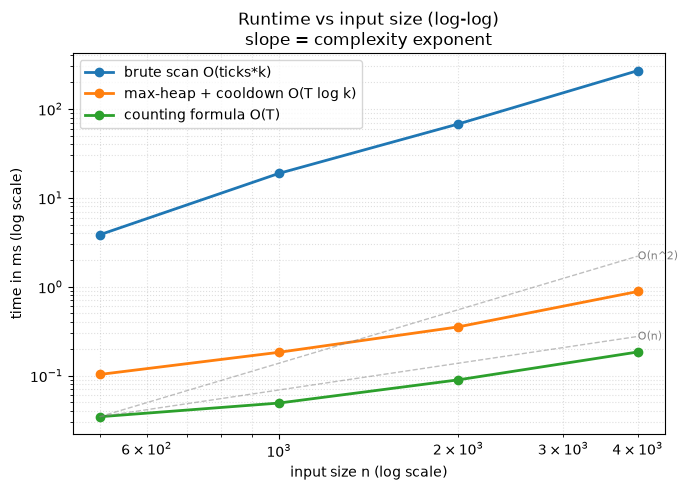

{'brute scan O(ticks*k)': [3.8312500109896064,
  18.81358295213431,
  67.68054200801998,
  269.2226660437882],
 'max-heap + cooldown O(T log k)': [0.10295805986970663,
  0.18287496641278267,
  0.3534160787239671,
  0.8833340834826231],
 'counting formula O(T)': [0.03445800393819809,
  0.04912493750452995,
  0.08962501306086779,
  0.18433306831866503]}

In [6]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(T):
    tasks = [i // 2 for i in range(T)]     # T/2 distinct types, two copies each -> k grows with T
    random.Random(T).shuffle(tasks)
    return (tasks, 2)
solutions = {
    "brute scan O(ticks*k)": least_interval_brute,
    "max-heap + cooldown O(T log k)": least_interval_heap,
    "counting formula O(T)": least_interval_formula,
}
sizes = [500, 1000, 2000, 4000]

benchmark(solutions, make_worst_case, sizes, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Heap Simulation](README.md) — a max-heap of task counts picks the biggest runnable pile each tick; a FIFO cooldown queue holds piles that just ran until they may rejoin the heap.
- **Heap + cooldown queue:** when an item you pop cannot be pushed back right away, park it in a queue with its release time. Same-length cooldowns release in the order they started, so a plain `deque` is enough (no second heap).
- **Skip idle time:** if the heap is empty, jump the clock to the queue front's release tick instead of looping through idle ticks.
- **Greedy + heap:** "always handle the largest remaining pile first" is the greedy; the heap makes each choice `O(log k)`.
- **Closed form from the simulation:** `max(len(tasks), (maxf - 1) * (n + 1) + count_max)` gives the length in `O(T)`; derive it from the frame picture, but use the heap when you need the actual order.
- **Signal:** "cooldown", "same item at least `n` apart", "no two adjacent equal", "minimum time / intervals to finish everything".
- **Related problems:** Last Stone Weight (plain max-heap simulation), Reorganize String (cooldown of 1, output the order), Rearrange String k Distance Apart, Single-Threaded CPU.
- **Common pitfalls:**
  1. Pushing a task back into the heap right after running it, ignoring the cooldown.
  2. Ticking through long idle stretches one by one instead of jumping the clock.
  3. In the formula, forgetting `count_max` (several types tie for the max) or the `max(len(tasks), ...)` when no idle is needed.
  4. Forgetting that `heapq` is a min-heap: the counts must be negated, and `+1` on a negated count means one copy fewer.